In [46]:
API_ecmwf = __import__("os").environ.get("ECMWF_API_KEY", "")

API_keys_ecmwf = {
    "url"   : "https://api.ecmwf.int/v1",
    "key"   : API_ecmwf,
    "email" : __import__("os").environ.get("ECMWF_API_EMAIL", "")
}


In [47]:
# check this out: https://github.com/ecmwf/notebook-examples/blob/master/opencharts/medium-mslp-rain.ipynb



In [48]:
# import metview as mv
from ecmwf.opendata import Client

In [49]:
client = Client("ecmwf", beta=False)

In [50]:
from ecmwfapi import ECMWFDataServer

In [51]:
server = ECMWFDataServer(
    url=API_keys_ecmwf["url"],
    key=API_keys_ecmwf["key"],
    email=API_keys_ecmwf["email"],
    verbose=False
)

In [52]:
# server.retrieve({
#     "class": "ti",
#     "dataset": "tigge",
#     "date": "2019-03-01",
#     "expver": "prod",
#     "grid": "2/2",
#     "area": "70/-130/30/-60",
#     "levtype": "sfc",
#     "origin": "ecmf",
#     "param": "168",
#     "step": "0/6",
#     "time": "00:00:00",
#     "type": "fc",
#     "target": "tigge-2019-03-01.grib",
# })

server.retrieve({
    "class": "ti",
    "dataset": "tigge",
    "date": "2019-03-01",
    "expver": "prod",
    "grid": "2/2",
    "area": "70/-130/30/-60",
    "levtype": "sfc",
    "origin": "ecmf",
    "param": "168",
    "step": "0/6",
    "time": "00:00:00",
    "type": "fc",
    "target": "tigge-2019-03-01.grib",
})

2026-02-27 16:46:51 ECMWF API python library 1.6.5
2026-02-27 16:46:51 ECMWF API at https://api.ecmwf.int/v1
2026-02-27 16:46:52 Welcome Jia Yuan Foo
2026-02-27 16:46:54 In case of problems, please check https://confluence.ecmwf.int/display/WEBAPI/Web+API+FAQ or contact servicedesk@ecmwf.int
2026-02-27 16:46:54 ------------ WARNING ------------
2026-02-27 16:46:54 Access to this dataset is transitioning to a new interface, dates to be announced soon
2026-02-27 16:46:54 For more information on how to access this data in the future, visit https://confluence.ecmwf.int/x/-wUiEw
2026-02-27 16:46:54 ---------------------------------
2026-02-27 16:46:55 Request submitted
2026-02-27 16:46:55 Request id: 69a159ff1c8e2efdf124ba0e
2026-02-27 16:46:55 Request is submitted
2026-02-27 16:46:57 Calling 'nice mars /tmp/20260227-0840/66/tmp-_mars-wCDqmm-1480db36a92dd0adce6d17721ab8a284.req'
2026-02-27 16:46:57 Forcing MIR_CACHE_PATH=/data/ec_coeff
2026-02-27 16:46:57 mars - WARN -
2026-02-27 16:46:57 m

In [53]:
import xarray as xr
import matplotlib.pyplot as plt
%matplotlib inline


In [54]:
ds = xr.load_dataset(
    "tigge-2019-03-01.grib",
    engine="cfgrib"
)
ds

Ignoring index file 'tigge-2019-03-01.grib.5b7b6.idx' older than GRIB file


<xarray.Dataset> Size: 7kB
Dimensions:            (step: 2, latitude: 21, longitude: 36)
Coordinates:
  * step               (step) timedelta64[ns] 16B 00:00:00 06:00:00
    valid_time         (step) datetime64[ns] 16B 2019-03-01 2019-03-01T06:00:00
  * latitude           (latitude) float64 168B 70.0 68.0 66.0 ... 34.0 32.0 30.0
  * longitude          (longitude) float64 288B 230.0 232.0 ... 298.0 300.0
    time               datetime64[ns] 8B 2019-03-01
    heightAboveGround  float64 8B 2.0
Data variables:
    d2m                (step, latitude, longitude) float32 6kB 249.3 ... 292.3
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-02-27T16:47 GRIB to CDM+CF via cfgrib-0.9.1...

In [55]:
dstut = xr.tutorial.load_dataset("era5-2mt-2019-03-uk.grib", engine="cfgrib")
dstut

<xarray.Dataset> Size: 5MB
Dimensions:     (time: 744, latitude: 33, longitude: 49)
Coordinates:
  * time        (time) datetime64[ns] 6kB 2019-03-01 ... 2019-03-31T23:00:00
    valid_time  (time) datetime64[ns] 6kB 2019-03-01 ... 2019-03-31T23:00:00
  * latitude    (latitude) float64 264B 58.0 57.75 57.5 ... 50.5 50.25 50.0
  * longitude   (longitude) float64 392B -10.0 -9.75 -9.5 -9.25 ... 1.5 1.75 2.0
    number      int64 8B 0
    step        timedelta64[ns] 8B 00:00:00
    surface     float64 8B 0.0
Data variables:
    t2m         (time, latitude, longitude) float32 5MB 282.4 282.3 ... 281.5
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-02-27T16:47 GRIB to CDM+CF via cfgrib-0.9.1...

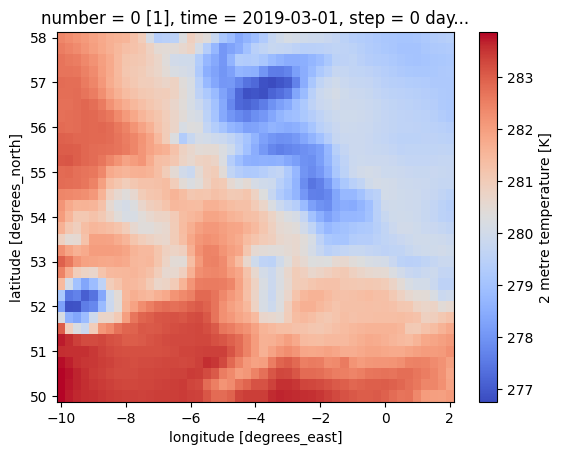

In [56]:
dstut.t2m[0].plot(cmap=plt.cm.coolwarm)

Text(0.5, 1.0, 'ERA5 - 2m temperature British Isles March 2019')

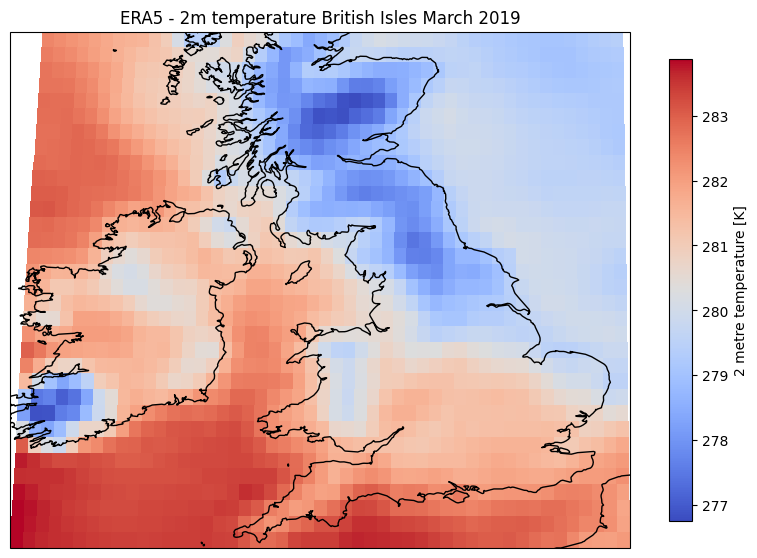

In [57]:
import cartopy.crs as ccrs
import cartopy

fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.Robinson())
ax.coastlines(resolution="10m")
plot = dstut.t2m[0].plot(
    cmap=plt.cm.coolwarm, 
    transform=ccrs.PlateCarree(), 
    cbar_kwargs={"shrink": 0.6}
)
plt.title("ERA5 - 2m temperature British Isles March 2019")


In [58]:
ds

<xarray.Dataset> Size: 7kB
Dimensions:            (step: 2, latitude: 21, longitude: 36)
Coordinates:
  * step               (step) timedelta64[ns] 16B 00:00:00 06:00:00
    valid_time         (step) datetime64[ns] 16B 2019-03-01 2019-03-01T06:00:00
  * latitude           (latitude) float64 168B 70.0 68.0 66.0 ... 34.0 32.0 30.0
  * longitude          (longitude) float64 288B 230.0 232.0 ... 298.0 300.0
    time               datetime64[ns] 8B 2019-03-01
    heightAboveGround  float64 8B 2.0
Data variables:
    d2m                (step, latitude, longitude) float32 6kB 249.3 ... 292.3
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-02-27T16:47 GRIB to CDM+CF via cfgrib-0.9.1...

In [59]:
type(dstut),type(ds)

(xarray.core.dataset.Dataset, xarray.core.dataset.Dataset)

In [60]:
dstut.data_vars

Data variables:
    t2m      (time, latitude, longitude) float32 5MB 282.4 282.3 ... 281.5 281.5

In [61]:
ds.data_vars

Data variables:
    d2m      (step, latitude, longitude) float32 6kB 249.3 248.6 ... 293.1 292.3

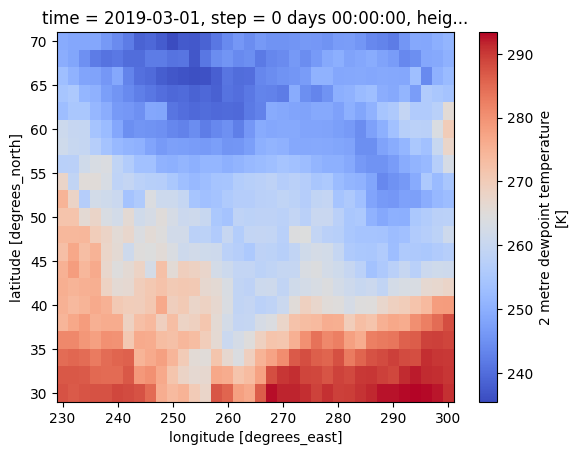

In [62]:
ds.d2m[0].plot(cmap=plt.cm.coolwarm)

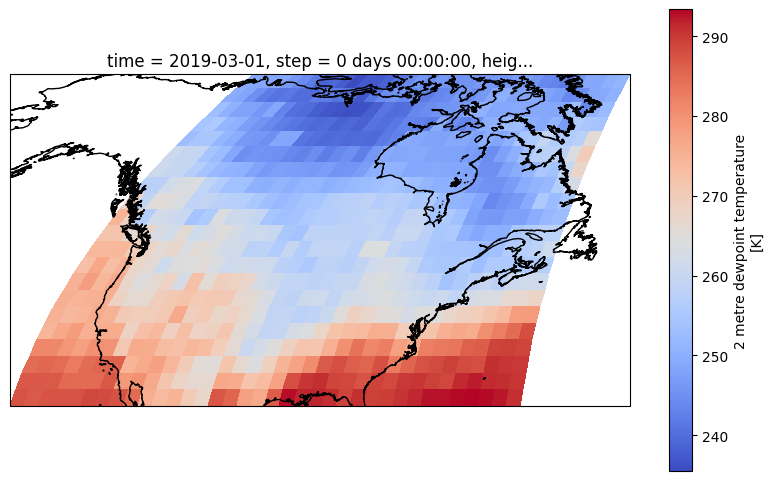

In [63]:
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.Robinson())
ax.coastlines(resolution="10m")
plot = ds.d2m[0].plot(
    cmap=plt.cm.coolwarm, 
    transform=ccrs.PlateCarree(), 
    cbar_kwargs={"shrink": 0.6}
)
# plt.title("ERA5 - 2m temperature British Isles March 2019")


In [64]:
# import pandas as pd
# import matplotlib.pyplot as plt
# import numpy as np
# from datetime import datetime



In [65]:
# # Create synthetic forecast data for demonstration
# # This simulates a 5-day temperature forecast for a region

# import numpy as np
# from datetime import datetime, timedelta

# # Create forecast data
# days = 5
# hours_per_day = 24
# lats = np.arange(0, 5, 0.5)  # Latitude range
# lons = np.arange(100, 110, 0.5)  # Longitude range

# # Generate synthetic temperature data (realistic values for tropical region)
# np.random.seed(42)
# base_temp = 28  # Base temperature in Celsius
# time_steps = days * 4  # 6-hourly forecasts

# # Create time array
# start_time = datetime.now()
# times = [start_time + timedelta(hours=6*i) for i in range(time_steps)]

# # Generate realistic temperature field with spatial variation
# forecast_data = {}
# for i, t in enumerate(times):
#     # Add diurnal cycle and spatial variation
#     hour_of_day = t.hour
#     diurnal = 5 * np.sin((hour_of_day - 6) * np.pi / 12)  # Max temp at 18:00
    
#     temp_field = base_temp + diurnal + np.random.normal(0, 1.5, (len(lats), len(lons)))
#     forecast_data[i] = temp_field

# print(f"✓ Forecast data created for {time_steps} time steps")
# print(f"  Spatial grid: {len(lats)} x {len(lons)} points")
# print(f"  Forecast period: {times[0]} to {times[-1]}")
# print(f"  Temperature range: {min(v.min() for v in forecast_data.values()):.1f}°C to {max(v.max() for v in forecast_data.values()):.1f}°C")

In [66]:
# # Load and plot the forecast data using cfgrib
# import cfgrib

# # Read GRIB file
# ds = cfgrib.open_datasets('forecast_data.grib')[0]
# print("Dataset loaded successfully!")
# print(f"Dataset variables: {list(ds.data_vars)}")
# print(f"Dataset dimensions: {dict(ds.dims)}")

# # Extract temperature data if available
# if 't2m' in ds.data_vars or '2t' in ds.data_vars:
#     temp_var = 't2m' if 't2m' in ds.data_vars else '2t'
#     temp_data = ds[temp_var]
    
#     # Convert from Kelvin to Celsius
#     temp_celsius = temp_data - 273.15
    
#     # Create visualization of first 4 time steps
#     n_times = min(4, temp_celsius.shape[0])
#     fig, axes = plt.subplots(2, 2, figsize=(15, 12))
#     fig.suptitle('ECMWF Ensemble Forecast - Temperature (°C)', fontsize=16, fontweight='bold')
    
#     for idx, ax in enumerate(axes.flat):
#         if idx < n_times:
#             # Get time step
#             im = ax.contourf(
#                 temp_celsius.longitude.values,
#                 temp_celsius.latitude.values,
#                 temp_celsius.values[idx],
#                 levels=20,
#                 cmap='RdYlBu_r'
#             )
#             ax.set_title(f'Time step {idx} - Forecast Hour')
#             ax.set_xlabel('Longitude')
#             ax.set_ylabel('Latitude')
#             plt.colorbar(im, ax=ax, label='Temp (°C)')
#         else:
#             ax.axis('off')
    
#     plt.tight_layout()
#     plt.savefig('forecast_temperature_plot.png', dpi=150, bbox_inches='tight')
#     plt.show()
    
#     print("\n✓ Forecast plot saved as 'forecast_temperature_plot.png'")
#     print(f"\nTemperature Statistics (°C):")
#     print(f"  Mean: {temp_celsius.values.mean():.2f}")
#     print(f"  Min: {temp_celsius.values.min():.2f}")
#     print(f"  Max: {temp_celsius.values.max():.2f}")
#     print(f"  Std: {temp_celsius.values.std():.2f}")
# else:
#     print("Temperature variable not found in dataset")
#     print(f"Available variables: {list(ds.data_vars)}")